### 1. Write a program to make a statistical estimate for π using one of the two methods suggested in ‘Maths13’

I will estimate $\pi$ using a Monte-Carlo simualtion of a $[1,1]$ square.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(1234)
plot_dir = "out/plots"


def estimate_pi(N, r=1.0):
    x = rng.random(N)
    y = rng.random(N)
    inside = np.count_nonzero(x**2 + y**2 < r**2)
    return 4 / r**2 * inside / N


for N in [10**2, 10**4, 10**6]:
    pi_hat = estimate_pi(N)
    print(f"N = {N}: pi_hat = {pi_hat:.5f}, error = {pi_hat - np.pi:+.5f}")

N = 100: pi_hat = 3.16000, error = +0.01841
N = 10000: pi_hat = 3.13680, error = -0.00479
N = 1000000: pi_hat = 3.13932, error = -0.00227


### 2. How accurate is the Monte Carlo?

Repeat pi estimate many times, fit the spread, and check 1.64/sqrt(N)

Mean pi: 3.1413
Standard deviation: 0.0166
Expected standard deviation: 0.0164
Error of the mean: 0.0004


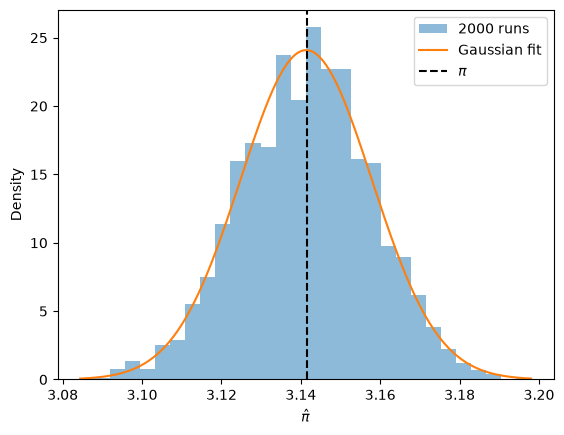

Measured slope: -0.502
Expected slope: -0.5


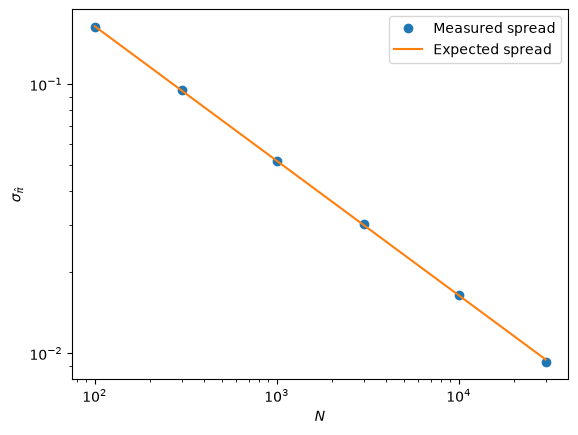


Radius squared: 1.000
Relative error * sqrt(N): 0.512
Expected value: 0.523

Radius squared: 0.667
Relative error * sqrt(N): 0.957
Expected value: 0.954


In [2]:
repeats = 2000
p = np.pi / 4

# Run the estimate lots of times and fit a Gaussian.
N = 10_000
estimates = np.array([estimate_pi(N) for _ in range(repeats)])
mean, sigma = norm.fit(estimates)

print(f"Mean pi: {mean:.4f}")
print(f"Standard deviation: {sigma:.4f}")
print(f"Expected standard deviation: {4 * np.sqrt(p * (1 - p) / N):.4f}")
print(f"Error of the mean: {sigma / np.sqrt(repeats):.4f}")

x = np.linspace(estimates.min(), estimates.max(), 300)
plt.hist(estimates, bins=30, density=True, alpha=0.5, label=f"{repeats} runs")
plt.plot(x, norm.pdf(x, mean, sigma), label="Gaussian fit")
plt.axvline(np.pi, color="black", linestyle="--", label=r"$\pi$")
plt.xlabel(r"$\hat{\pi}$")
plt.ylabel("Density")
plt.legend()
plt.savefig(f"{plot_dir}/pi_histogram.png", dpi=150)
plt.show()

# See how the standard deviation changes with N.
sample_sizes = np.array([100, 300, 1000, 3000, 10_000, 30_000])
sigmas = [np.std([estimate_pi(N) for _ in range(repeats)]) for N in sample_sizes]
slope, intercept = np.polyfit(np.log(sample_sizes), np.log(sigmas), 1)

print(f"Measured slope: {slope:.3f}")
print("Expected slope: -0.5")

plt.loglog(sample_sizes, sigmas, "o", label="Measured spread")
plt.loglog(sample_sizes, 4 * np.sqrt(p * (1 - p) / sample_sizes), label="Expected spread")
plt.xlabel("$N$")
plt.ylabel(r"$\sigma_{\hat{\pi}}$")
plt.legend()
plt.savefig(f"{plot_dir}/pi_scaling.png", dpi=150)
plt.show()

# Compare the relative error for two different radii.
N = 10_000
for r_squared in [1.0, 2 / 3]:
    estimates = [estimate_pi(N, np.sqrt(r_squared)) for _ in range(repeats)]
    p_inside = np.pi * r_squared / 4
    measured = np.std(estimates) / np.pi * np.sqrt(N)
    expected = np.sqrt((1 - p_inside) / p_inside)

    print(f"\nRadius squared: {r_squared:.3f}")
    print(f"Relative error * sqrt(N): {measured:.3f}")
    print(f"Expected value: {expected:.3f}")

In [3]:
# Estimate pi using the first 10 factors of Viete's product.
x = 0
product = 1

for n in range(1, 11):
    x = np.sqrt((1 + x) / 2)
    product = product * x
    print(f"{n} factors: pi_hat = {2 / product:.7f}, error = {2 / product - np.pi:.1e}")

1 factors: pi_hat = 2.8284271, error = -3.1e-01
2 factors: pi_hat = 3.0614675, error = -8.0e-02
3 factors: pi_hat = 3.1214452, error = -2.0e-02
4 factors: pi_hat = 3.1365485, error = -5.0e-03
5 factors: pi_hat = 3.1403312, error = -1.3e-03
6 factors: pi_hat = 3.1412773, error = -3.2e-04
7 factors: pi_hat = 3.1415138, error = -7.9e-05
8 factors: pi_hat = 3.1415729, error = -2.0e-05
9 factors: pi_hat = 3.1415877, error = -4.9e-06
10 factors: pi_hat = 3.1415914, error = -1.2e-06


Viete's product converges *much* quicker. 10 factors gets an error of about 1e-6, Monte Carlo would need around 1e12 points for that.

### 3. The 1D Ising model

Ring of 100 spins with $J=1$ and $k_B=1$. Start with all spins up, discard 1,000 sweeps, then measure the energy once per sweep.

In [4]:
def energy_1d(spins):
    # Each spin times its left neighbour, np.roll joins the ends into a ring.
    return -np.sum(spins * np.roll(spins, 1))


def sweep_1d(spins, T):
    # One sweep is N attempted flips.
    N = len(spins)
    sites = rng.integers(N, size=N)
    randoms = rng.random(N)

    for i, u in zip(sites, randoms):
        dE = 2 * spins[i] * (spins[i - 1] + spins[(i + 1) % N])

        if dE <= 0 or u < np.exp(-dE / T):
            spins[i] = -spins[i]


def simulate_1d(T, N=100, equil_sweeps=1000, measure_sweeps=5000):
    spins = np.ones(N, dtype=int)

    for _ in range(equil_sweeps):
        sweep_1d(spins, T)

    energies = np.zeros(measure_sweeps)
    for k in range(measure_sweeps):
        sweep_1d(spins, T)
        energies[k] = energy_1d(spins)

    e = np.mean(energies) / N
    C = np.var(energies) / (N * T**2)
    return e, C

a) and b) Energy and specific heat per spin, compared to the exact transfer matrix results.

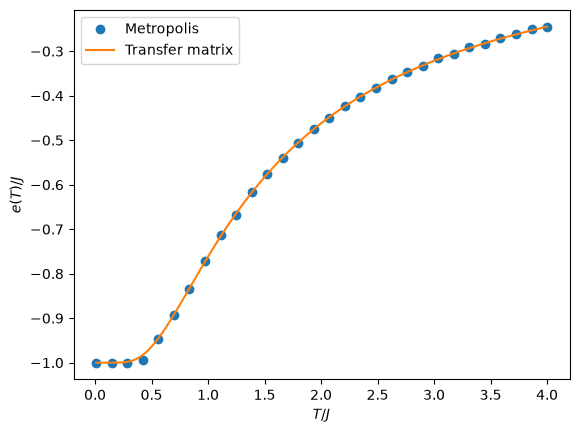

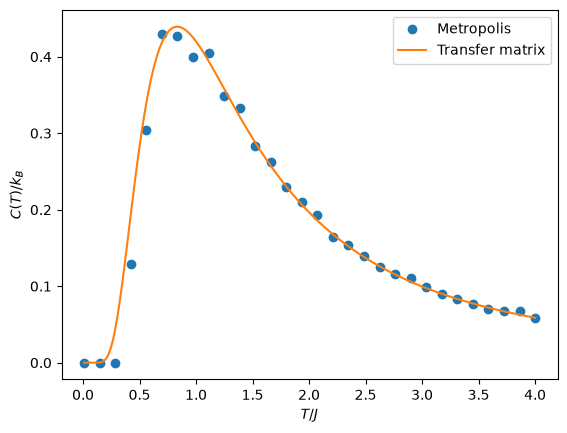

In [5]:
temperatures = np.linspace(0.01, 4, 30)
results = np.array([simulate_1d(T) for T in temperatures])
e_1d = results[:, 0]
C_1d = results[:, 1]

# Exact results from the transfer matrix (infinite chain).
T_fine = np.linspace(0.01, 4, 400)
e_exact = -np.tanh(1 / T_fine)
C_exact = (1 / T_fine)**2 / np.cosh(1 / T_fine)**2

plt.plot(temperatures, e_1d, "o", label="Metropolis")
plt.plot(T_fine, e_exact, label="Transfer matrix")
plt.xlabel("$T/J$")
plt.ylabel("$e(T)/J$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_1d_energy.png", dpi=150)
plt.show()

plt.plot(temperatures, C_1d, "o", label="Metropolis")
plt.plot(T_fine, C_exact, label="Transfer matrix")
plt.xlabel("$T/J$")
plt.ylabel("$C(T)/k_B$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_1d_specific_heat.png", dpi=150)
plt.show()

### 4. The 2D Ising model

Same Metropolis loop on a 20x20 lattice, now with four neighbours. Also measure $|m|$. Takes about 5 minutes.

In [6]:
def energy_2d(spins):
    # Each spin times its upper and left neighbours, so every bond is counted once.
    return -np.sum(spins * (np.roll(spins, 1, axis=0) + np.roll(spins, 1, axis=1)))


def sweep_2d(spins, T):
    L = len(spins)
    rows = rng.integers(L, size=L * L)
    cols = rng.integers(L, size=L * L)
    randoms = rng.random(L * L)

    for i, j, u in zip(rows, cols, randoms):
        neighbours = (spins[i - 1, j] + spins[(i + 1) % L, j]
                      + spins[i, j - 1] + spins[i, (j + 1) % L])
        dE = 2 * spins[i, j] * neighbours

        if dE <= 0 or u < np.exp(-dE / T):
            spins[i, j] = -spins[i, j]


def simulate_2d(T, L=20, equil_sweeps=1000, measure_sweeps=3000):
    N = L * L
    spins = np.ones((L, L), dtype=int)

    for _ in range(equil_sweeps):
        sweep_2d(spins, T)

    energies = np.zeros(measure_sweeps)
    magnetisations = np.zeros(measure_sweeps)
    for k in range(measure_sweeps):
        sweep_2d(spins, T)
        energies[k] = energy_2d(spins)
        magnetisations[k] = abs(np.sum(spins))

    C = np.var(energies) / (N * T**2)
    m = np.mean(magnetisations) / N
    return C, m

a) Specific heat and magnetisation, compared to Onsager's exact results.

C peaks at T = 2.36
Exact Tc = 2.269


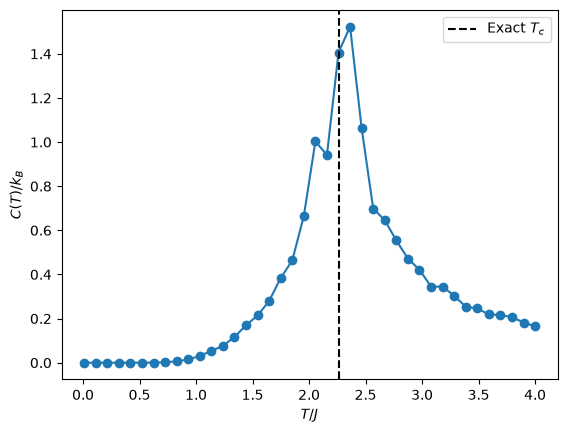

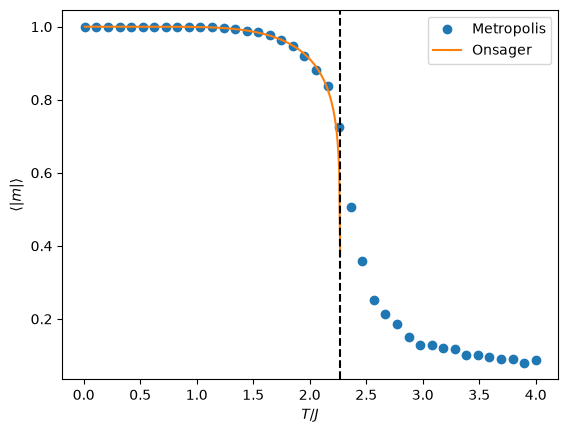

In [7]:
temperatures = np.linspace(0.01, 4, 40)
results = np.array([simulate_2d(T) for T in temperatures])
C_2d = results[:, 0]
m_2d = results[:, 1]

# Onsager's exact results for the infinite lattice.
Tc = 2 / np.log(1 + np.sqrt(2))
T_below = np.linspace(0.01, 2.269, 300)
m_exact = (1 - np.sinh(2 / T_below)**-4)**(1 / 8)

print(f"C peaks at T = {temperatures[np.argmax(C_2d)]:.2f}")
print(f"Exact Tc = {Tc:.3f}")

plt.plot(temperatures, C_2d, "o-")
plt.axvline(Tc, color="black", linestyle="--", label="Exact $T_c$")
plt.xlabel("$T/J$")
plt.ylabel("$C(T)/k_B$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_2d_specific_heat.png", dpi=150)
plt.show()

plt.plot(temperatures, m_2d, "o", label="Metropolis")
plt.plot(T_below, m_exact, label="Onsager")
plt.axvline(Tc, color="black", linestyle="--")
plt.xlabel("$T/J$")
plt.ylabel(r"$\langle |m| \rangle$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_2d_magnetisation.png", dpi=150)
plt.show()

Snapshots of a 40x40 lattice below, at and above $T_c$.

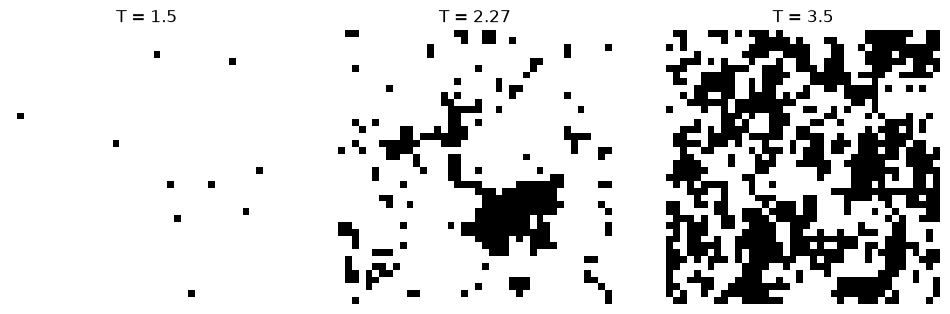

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, T in zip(axes, [1.5, 2.27, 3.5]):
    spins = np.ones((40, 40), dtype=int)
    for _ in range(1000):
        sweep_2d(spins, T)

    ax.imshow(spins, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"T = {T}")
    ax.axis("off")

plt.savefig(f"{plot_dir}/ising_2d_snapshots.png", dpi=150)
plt.show()

### 5. The phase transition and correlation length

b) Above $T_c$, correlate the row averages a distance $r$ apart and fit $G(r) \sim e^{-r/\xi}$. Then fit $\xi \sim (T-T_c)^{-\nu}$. Takes about 10 minutes.

In [9]:
def row_correlation(T, L=40, equil_sweeps=2000, measure_sweeps=5000, r_max=10):
    spins = np.ones((L, L), dtype=int)

    for _ in range(equil_sweeps):
        sweep_2d(spins, T)

    G = np.zeros(r_max + 1)
    for _ in range(measure_sweeps):
        sweep_2d(spins, T)
        row_means = np.mean(spins, axis=1)
        col_means = np.mean(spins, axis=0)

        # Multiply each row average by the one r rows away, same for columns.
        for r in range(r_max + 1):
            G[r] += np.mean(row_means * np.roll(row_means, r))
            G[r] += np.mean(col_means * np.roll(col_means, r))

    return G / (2 * measure_sweeps)

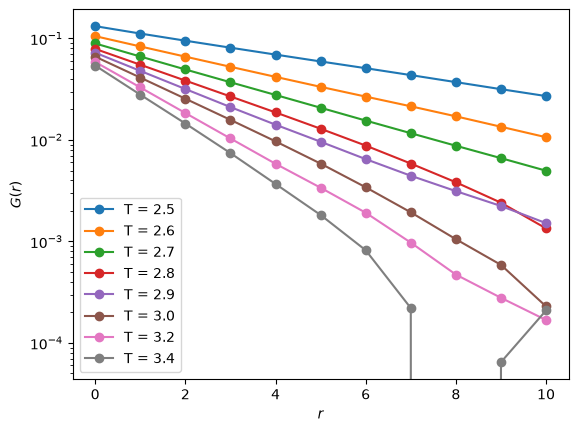

Measured xi: [6.34 4.39 3.43 2.78 2.43 2.09 1.73 1.52]
Exact xi:    [5.96 4.27 3.37 2.8  2.42 2.14 1.75 1.51]
nu = 0.91
Expected nu = 1


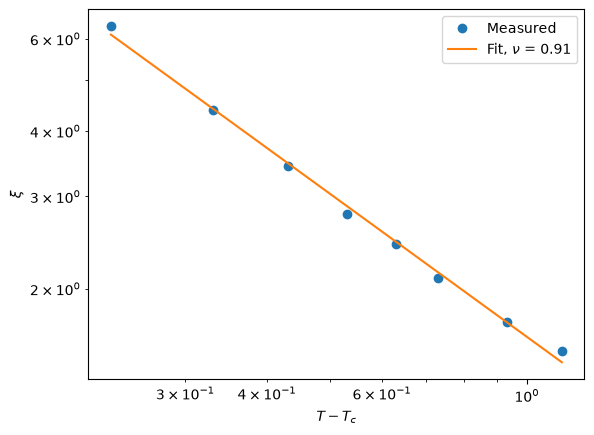

In [10]:
corr_temperatures = np.array([2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.2, 3.4])
r = np.arange(11)
xis = []

# The slope of log G against r is -1/xi. Only fit where G is well above the noise.
for T in corr_temperatures:
    G = row_correlation(T)
    fit_range = G > 0.2 * G[0]
    slope, intercept = np.polyfit(r[fit_range], np.log(G[fit_range]), 1)
    xis.append(-1 / slope)
    plt.semilogy(r, G, "o-", label=f"T = {T}")

plt.xlabel("$r$")
plt.ylabel("$G(r)$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_2d_correlation.png", dpi=150)
plt.show()

# The slope of log xi against log (T - Tc) is -nu.
xis = np.array(xis)
xi_exact = 1 / (np.log(1 / np.tanh(1 / corr_temperatures)) - 2 / corr_temperatures)
slope, intercept = np.polyfit(np.log(corr_temperatures - Tc), np.log(xis), 1)
nu = -slope

print("Measured xi:", np.round(xis, 2))
print("Exact xi:   ", np.round(xi_exact, 2))
print(f"nu = {nu:.2f}")
print("Expected nu = 1")

plt.loglog(corr_temperatures - Tc, xis, "o", label="Measured")
plt.loglog(corr_temperatures - Tc, np.exp(intercept) * (corr_temperatures - Tc)**slope,
           label=rf"Fit, $\nu$ = {nu:.2f}")
plt.xlabel("$T - T_c$")
plt.ylabel(r"$\xi$")
plt.legend()
plt.savefig(f"{plot_dir}/ising_2d_xi_power_law.png", dpi=150)
plt.show()